In [ ]:
import numpy as np

In [ ]:
class MyLinear:
    def __init__(self, input_size, output_size):
        self.input_size = input_size
        self.output_size = output_size
        self.weight = np.random.normal(
            0, np.sqrt(2 / input_size), size=(output_size, input_size)
        )
        self.bias = np.zeros(output_size)

    def forward(self, X):
        return X @ self.weight.T + self.bias

    def __call__(self, X):
        return self.forward(X)

In [ ]:
class MyReLU:
    def __init__(self):
        pass

    def forward(self, X):
        return np.maximum(0, X)

    def __call__(self, X):
        return self.forward(X)


class MyIdentity:
    def __init__(self):
        pass

    def forward(self, X):
        return X

    def __call__(self, X):
        return self.forward(X)

In [ ]:
class MyModel:
    def __init__(self, dim_list):
        self.num_layers = len(dim_list) - 1
        self.module_list = []
        for l in range(self.num_layers):
            self.module_list.append(MyLinear(dim_list[l], dim_list[l + 1]))
            if l < self.num_layers - 1:
                self.module_list.append(MyReLU())
            else:
                self.module_list.append(MyIdentity())

        self.Y = [None] * (self.num_layers + 1)
        self.Z = [None] * (self.num_layers + 1)
        self.delta_Y = [None] * (self.num_layers + 1)
        self.delta_Z = [None] * (self.num_layers + 1)
        self.delta_W = [None] * (self.num_layers + 1)
        self.delta_b = [None] * (self.num_layers + 1)

    def forward(self, inputs):
        self.Y[0] = inputs
        for l in range(1, self.num_layers + 1):
            self.Z[l] = self.module_list[2 * l - 2](self.Y[l - 1])
            self.Y[l] = self.module_list[2 * l - 1](self.Z[l])
        return self.Y[-1]

    def backward(self, outputs):
        logits = self.Y[-1]
        delta_Y = np.exp(logits) / np.sum(
            np.exp(logits), axis=1, keepdims=True
        )
        delta_Y[range(delta_Y.shape[0]), outputs] -= 1
        self.delta_Y[-1] = delta_Y

        for l in range(self.num_layers, 0, -1):
            if isinstance(self.module_list[2 * l - 1], MyReLU) == True:
                d_phi = (self.Y[l] > 0)
            else:
                d_phi = 1

            self.delta_Z[l] = d_phi * self.delta_Y[l]
            self.delta_b[l] = np.sum(self.delta_Z[l], axis=0)
            self.delta_W[l] = self.delta_Z[l].T @ self.Y[l - 1]
            self.delta_Y[l - 1] = self.delta_Z[l] @ self.module_list[2 * (l - 1)].weight

    def __call__(self, inputs):
        return self.forward(inputs)

In [ ]:
class MyAdam:
    def __init__(self, model, lr = 0.001, beta1=0.9, beta2=0.999, epsilon=1e-8):
        self.model = model
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.epsilon = epsilon

        self.num_layers = model.num_layers
        self.k = -1

        self.v_weight_list = [None]
        self.s_weight_list = [None]
        self.v_bias_list = [None]
        self.s_bias_list = [None]

        for l in range(1, self.num_layers + 1):
            self.v_weight_list.append(np.zeros_like(model.module_list[2 * l - 2].weight))
            self.s_weight_list.append(np.zeros_like(model.module_list[2 * l - 2].weight))

            self.v_bias_list.append(np.zeros_like(model.module_list[2 * l - 2].bias))
            self.s_bias_list.append(np.zeros_like(model.module_list[2 * l - 2].bias))
    def step(self):
        self.k += 1


        for l in range(1, self.num_layers + 1):
            self.v_weight_list[l] = self.beta1 * self.v_weight_list[l] + (1 - self.beta1) * self.model.delta_W[l]
            self.v_bias_list[l] = self.beta1 * self.v_bias_list[l] + (1 - self.beta1) * self.model.delta_b[l]

            self.s_weight_list[l] = self.beta2 * self.s_weight_list[l] + (1 - self.beta2) * self.model.delta_W[l] ** 2
            self.s_bias_list[l] = self.beta2 * self.s_bias_list[l] + (1 - self.beta2) * self.model.delta_b[l] ** 2

            v_weight_hat = self.v_weight_list[l] / (1 - self.beta1**(self.k + 1))
            v_bias_hat = self.v_bias_list[l] / (1 - self.beta1**(self.k + 1))
            s_weight_hat = self.s_weight_list[l] / (1 - self.beta2**(self.k + 1))
            s_bias_hat = self.s_bias_list[l] / (1 - self.beta2**(self.k + 1))

            self.model.module_list[2 * l - 2].weight -= self.lr * v_weight_hat / (np.sqrt(s_weight_hat) + self.epsilon)
            self.model.module_list[2 * l - 2].bias -= self.lr * v_bias_hat / (np.sqrt(s_bias_hat) + self.epsilon)


In [ ]:
from sklearn.datasets import fetch_openml
mnist = fetch_openml("mnist_784")
inputs, outputs = mnist["data"], mnist["target"]

inputs = np.array(inputs)
outputs = np.array(outputs.astype(int))


sample_size = 2000
np.random.seed(42)
indices = np.random.choice(inputs.shape[0], sample_size, replace = False)

np.random.seed()

inputs = inputs[indices]
outputs = outputs[indices]

inputs = inputs/255

In [ ]:
from sklearn.model_selection import train_test_split

random_state = 42
inputs_train, inputs_test, outputs_train, outputs_test = train_test_split(inputs, outputs, test_size=0.2, random_state=random_state)


In [ ]:
dim_list = [784, 64, 10]
model = MyModel(dim_list)

100%|██████████| 100/100 [00:19<00:00,  5.20it/s]


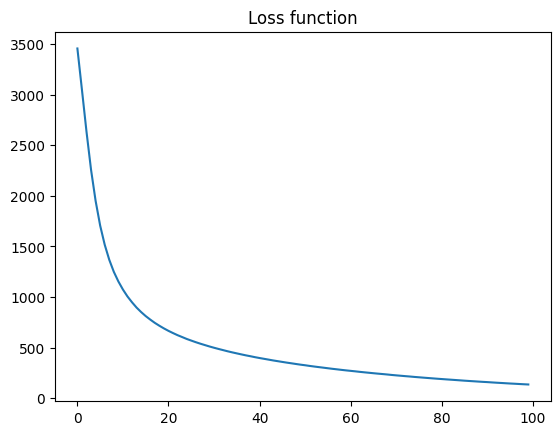

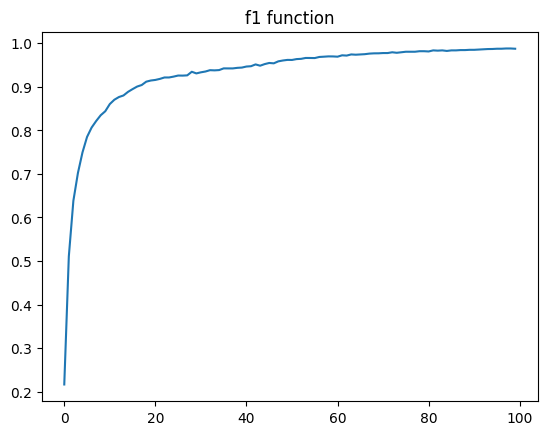

100
100
[np.float64(3454.719487814861), np.float64(3046.1265596013027), np.float64(2632.5387140506305), np.float64(2255.6283259173015), np.float64(1949.1055302406996), np.float64(1705.0711668885142), np.float64(1515.9101710667708), np.float64(1366.9970867715629), np.float64(1248.1549631969883), np.float64(1153.052419854852), np.float64(1073.1902872140977), np.float64(1004.6753521195501), np.float64(947.0234785281493), np.float64(894.7958186595404), np.float64(850.6619398377568), np.float64(810.9699465069876), np.float64(776.4032177285785), np.float64(744.1214731064172), np.float64(715.7111152767059), np.float64(689.2473694678727), np.float64(665.0775615325756), np.float64(643.1911623883504), np.float64(622.3988849305113), np.float64(604.0275364810959), np.float64(585.3042907449803), np.float64(569.0564761636201), np.float64(553.2396364216868), np.float64(538.3834979560097), np.float64(524.6436249437031), np.float64(510.9372445080638), np.float64(498.3099456391857), np.float64(486.31833

In [ ]:
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

sample_size_train = inputs_train.shape[0]

eta = 1e-4
optimizer = MyAdam(model, lr= eta)

num_epochs = 100
batch_size = 32
loss_list = []
f1_list = []
for n in tqdm(range(num_epochs)):
    indices = np.arange(sample_size_train)
    np.random.shuffle(indices)

    for i in range(0, sample_size_train, batch_size):
        inputs = inputs_train[indices[i:np.minimum(i + batch_size, sample_size_train)]]
        outputs = outputs_train[indices[i:np.minimum(i + batch_size, sample_size_train)]]

        model(inputs)
        model.backward(outputs)
        optimizer.step()

    logits = model(inputs_train)
    pred_prob = np.exp(logits) / np.sum(np.exp(logits), axis=1, keepdims=True)
    loss_list.append(-np.sum(np.log(pred_prob[np.arange(sample_size_train), outputs_train])))

    pred_label = np.argmax(pred_prob, axis=1)
    f1_list.append(f1_score(outputs_train, pred_label, average='macro'))
plt.plot(loss_list)
plt.title("Loss function")
plt.show()

plt.plot(f1_list)
plt.title("f1 function")
plt.show()
print(len(loss_list))
print(len(f1_list))
print(loss_list)
print(f1_list)